# Coûts d'assurance maladie : visite guidée

Ce notebook présente les résultats du pipeline (`make run`). Il n'entraîne rien : il appelle le package `insurance_costs` et lit les artefacts. La source de vérité reste le code testé dans `src/`. Le rapport complet est publié sur [GitHub Pages](https://fleury-fcn.github.io/health-insurance-cost-analysis/).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from insurance_costs.data import load_clean
from insurance_costs.config import ARTIFACT_DIR, FIGURE_DIR
load = lambda name: json.loads((ARTIFACT_DIR / name).read_text(encoding='utf-8'))
pd.set_option('display.float_format', '{:,.2f}'.format)
df = load_clean()
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


## 1. Qualité des données
Un doublon exact supprimé, aucune valeur manquante ni impossible. Les coûts extrêmes sont conservés : ce sont surtout des fumeurs.

In [2]:
q = load('data_quality.json')
pd.DataFrame(q['cleaning_log'])[['action', 'rows_removed', 'reason']]

,action,rows_removed,reason
0,Normalisation des types et des libellés,0,Libellés en minuscules sans espaces ; conversi...
1,Suppression des doublons exacts,1,"Sans identifiant, deux lignes identiques au ce..."
2,Suppression des lignes incomplètes,0,Aucune imputation : la part de manquants est n...
3,Exclusion des valeurs impossibles,0,Hors bornes de plausibilité ou modalité inconn...
4,Conservation des valeurs extrêmes de coûts,0,Les coûts élevés sont le risque que l'assureur...


In [3]:
q['charge_outlier_profile']

{'count': 139,
 'share_smokers': 0.9784172661870504,
 'share_smokers_overall': 0.2049364248317128,
 'share_obese': 0.9640287769784173}

## 2. Exploration
Trois bandes de coûts selon l'âge, et une rupture à IMC 30 réservée aux fumeurs : c'est une **interaction**.

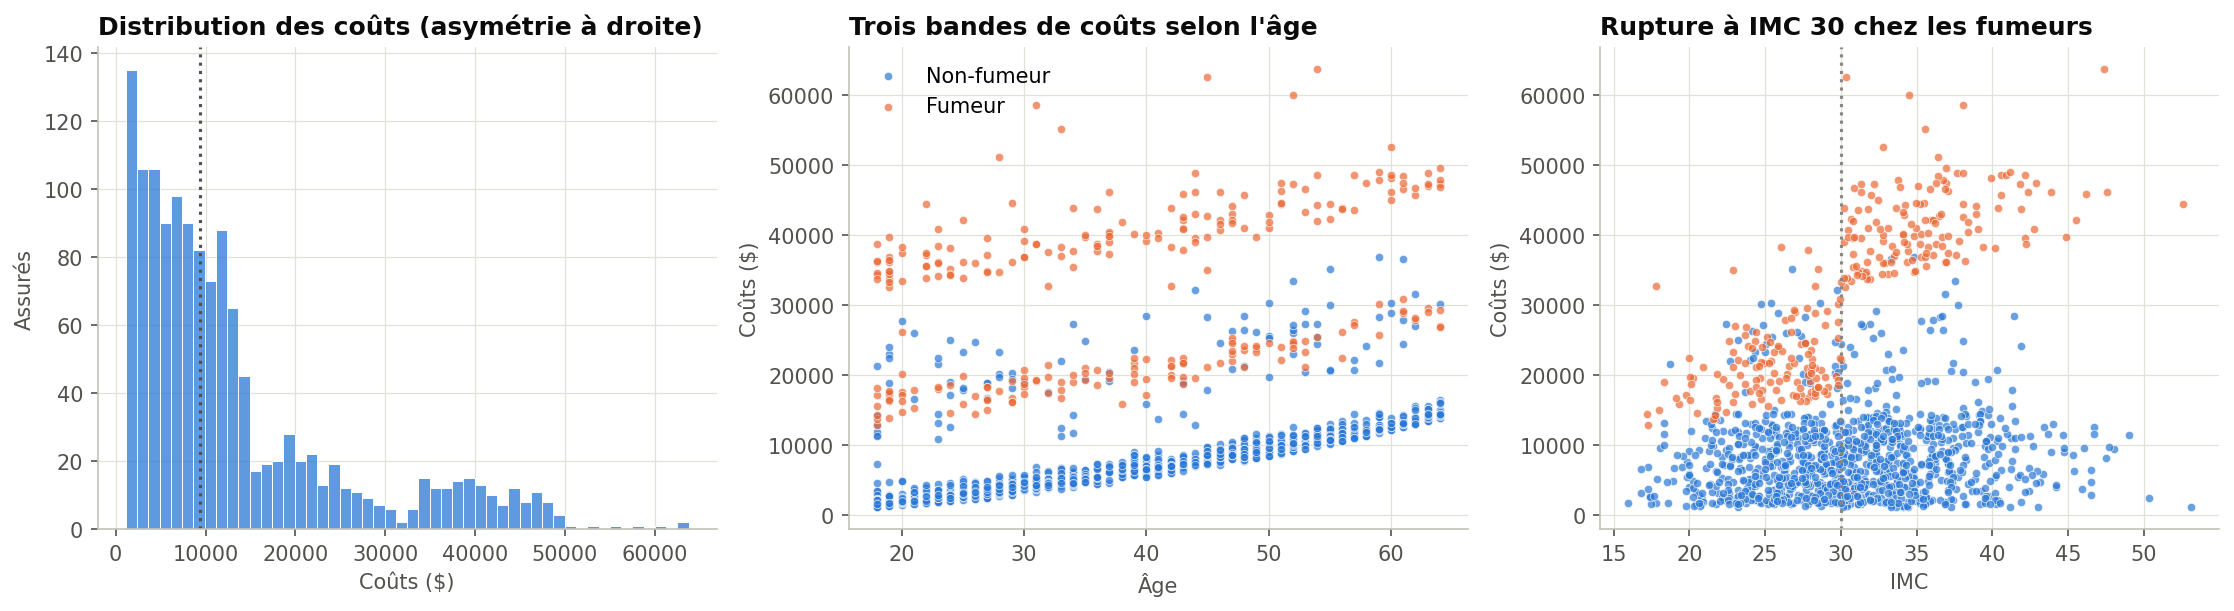

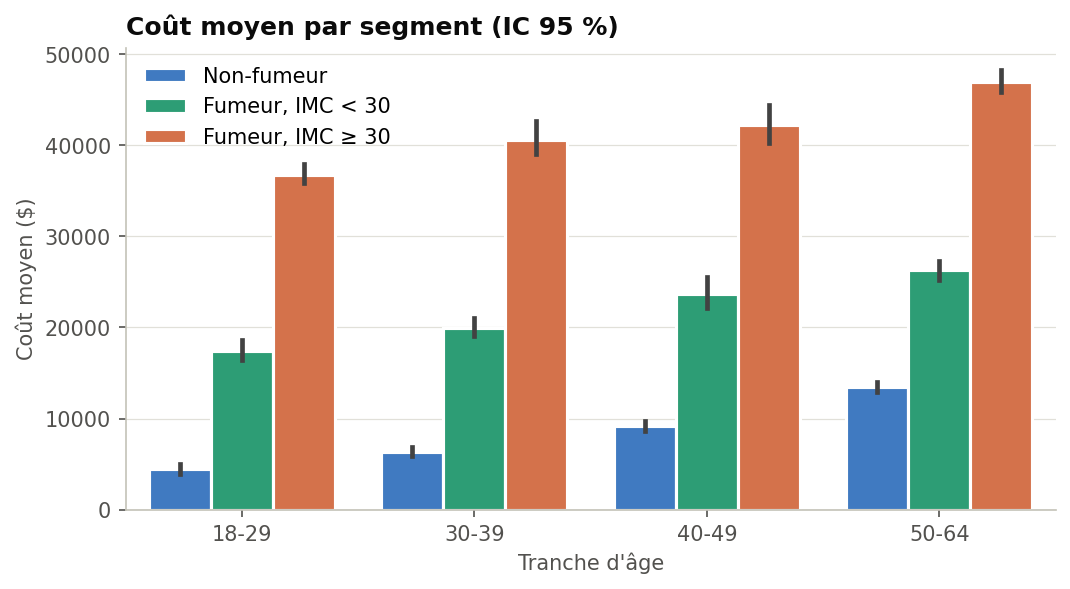

In [4]:
display(Image(FIGURE_DIR / 'eda_overview.png'))
display(Image(FIGURE_DIR / 'eda_segments.png'))

In [5]:
df.groupby(['smoker', df.bmi >= 30]).charges.agg(['count', 'mean', 'median'])

count      mean    median
smoker bmi                             
no     False    502  7,977.03  6,761.62
       True     561  8,855.53  8,083.92
yes    False    129 21,363.22 20,167.34
       True     145 41,557.99 40,904.20

## 3. Inférence
Hypothèses vérifiées (non-normalité, hétéroscédasticité), donc tests robustes, tailles d'effet et IC.

In [6]:
for c in load('inference.json')['conclusions']:
    display(Markdown('- ' + c))

- Hypothèses : les coûts ne sont normaux dans aucun groupe (Shapiro-Wilk p min = 1.5e-28) et les variances sont hétérogènes (Levene p < 0,001). Le t de Student et l'ANOVA classique sont donc fournis à titre indicatif ; les conclusions reposent sur Welch, Mann-Whitney, Kruskal-Wallis, Alexander-Govern et le bootstrap.

- Tabagisme : les fumeurs coûtent en moyenne 23 610 $ de plus (IC 95 % bootstrap [22 186 ; 25 039] $). Mann-Whitney p < 0,001, corrélation rang-bisériale 0,95, g de Hedges 3,16 : effet très fort, résultat central de l'étude.

- Sexe : écart brut de 1 405 $ en faveur des femmes (Welch p = 0,034, mais Mann-Whitney p = 0,694), effet négligeable. Cet écart brut vient surtout de la plus forte proportion de fumeurs chez les hommes. À profil égal (âge, IMC, enfants, tabagisme), le sens s'inverse : -8,3% pour un homme (p < 0,001, η² partiel 0,010). L'effet est détectable mais faible, et le sexe est un critère tarifaire interdit dans l'UE (arrêt Test-Achats, 2011).

- Région : ANOVA p = 0,033 mais Kruskal-Wallis p = 0,202 et Alexander-Govern p = 0,053 (η² = 0,007, effet négligeable) : pas d'écart brut robuste. Ajusté des autres facteurs (p < 0,001, η² partiel 0,019), on observe un effet modéré par rapport au nord-est : northwest -5,8%, southeast -13,9%, southwest -12,8%.

- Tabagisme × région : χ² p = 0,064, V de Cramér 0,07. Tabagisme × sexe : χ² p = 0,006, V = 0,07 (effectifs attendus tous ≥ 5, condition du χ² respectée). Dans les deux cas, l'association est faible.

- Corrélations : âge r = 0,30 (IC 95 % [0,25 ; 0,35]), IMC r = 0,20 (IC 95 % [0,15 ; 0,25]).

- Tests multiples : après correction de Holm sur les 8 tests de la famille, restent significatifs au seuil de 5 % : smoker (Mann-Whitney), children (Kruskal-Wallis), sex x smoker (chi2), sex | controls (F), region | controls (F).

- Un p-value très faible ne mesure pas l'ampleur d'un effet. Les tailles d'effet montrent que le tabagisme écrase tous les autres facteurs catégoriels.

## 4. Feature engineering (ablation en CV)

In [7]:
pd.DataFrame(load('feature_ablation.json')).T[['cv_rmse', 'cv_r2']]

,cv_rmse,cv_r2
Ridge - variables brutes,"6,297.16",0.72
Ridge - avec interactions,"4,606.82",0.85
Ridge log (smearing) - variables brutes,"9,744.78",0.34
Ridge log (smearing) - avec interactions,"6,115.83",0.74
Ridge log (smearing) - interactions sans age_smoker,"10,169.00",0.29
Ridge - interactions sans obese,"4,591.43",0.85
Ridge - interactions sans smoker_obese,"4,953.02",0.83
Ridge - interactions sans bmi_smoker,"4,667.31",0.85
Ridge - interactions sans age_smoker,"4,601.77",0.85
Ridge - interactions sans age_sq,"4,656.65",0.85


## 5. Modèles
Sélection sur la RMSE de validation croisée, évaluation unique sur le test.

In [8]:
m = load('metrics.json')
rows = {n: {'cv_rmse': v['cv_rmse'], **{k: v['test'][k] for k in ['rmse', 'mae', 'r2', 'gini', 'calibration_ratio']}} for n, v in m['models'].items()}
print('Meilleur modèle :', m['best_model'])
pd.DataFrame(rows).T.sort_values('cv_rmse')

Meilleur modèle : Lasso


,cv_rmse,rmse,mae,r2,gini,calibration_ratio
Lasso,"4,597.10","3,345.24","1,991.95",0.92,0.95,1.05
Ridge,"4,605.90","3,368.16","2,003.42",0.92,0.95,1.05
XGBoost,"4,704.15","3,402.74","2,105.54",0.92,0.95,1.05
Random Forest,"4,705.21","3,376.41","2,082.42",0.92,0.95,1.05
LightGBM,"4,716.75","3,463.32","2,127.29",0.92,0.95,1.05
GLM Gamma (lien log),"5,110.82","4,312.59","2,697.71",0.87,0.94,1.06
Ridge cible log,"5,862.50","5,380.60","3,405.67",0.80,0.94,1.15
Baseline (moyenne),"12,098.18","12,012.59","9,080.77",-0.00,0.00,1.03


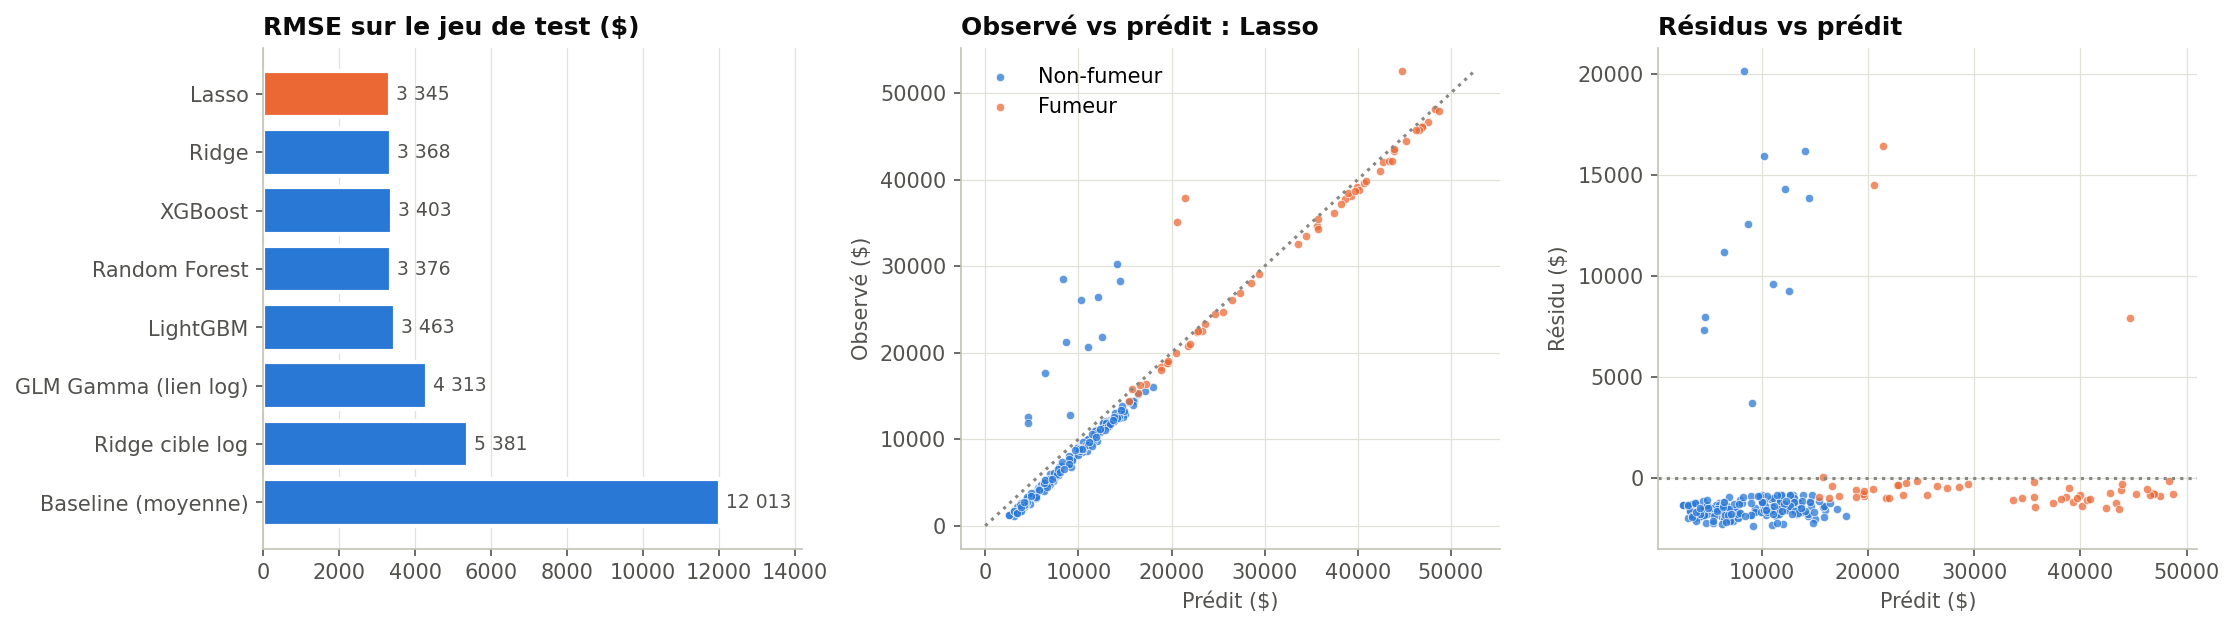

{'best': 'Lasso',
 'runner_up': 'Ridge',
 'mean_diff': -23.261850132912915,
 'ci95': [-51.2379270287088, 3.80253051702347],
 'prob_a_better': 0.95}

In [9]:
display(Image(FIGURE_DIR / 'model_overview.png'))
m['best_vs_runner_up']

## 6. Interprétation et équité

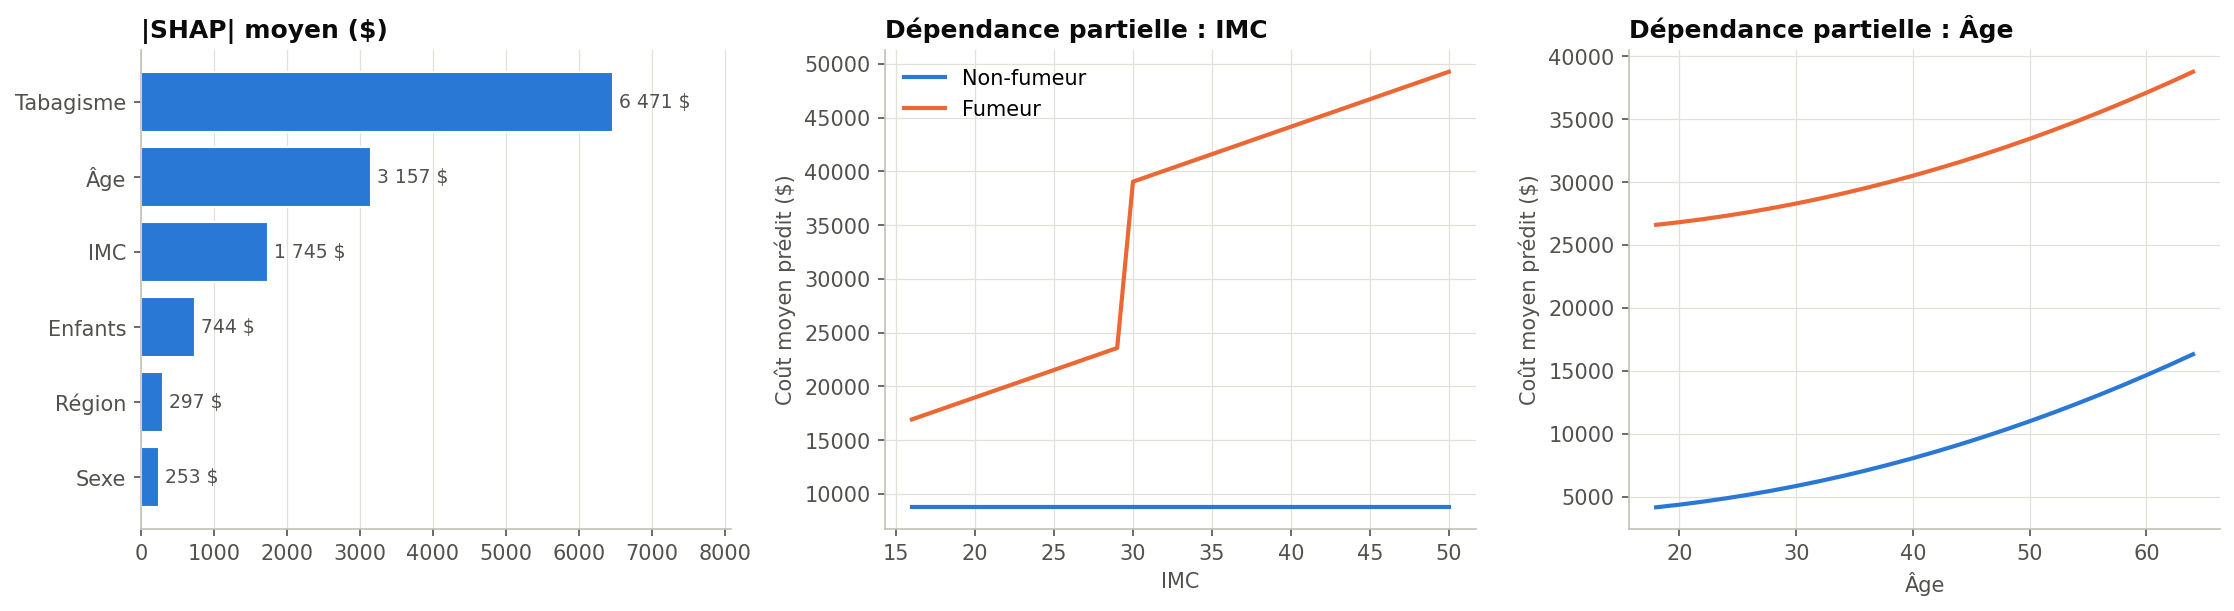

- Hiérarchie (SHAP) : Tabagisme > Âge > IMC > Enfants > Région > Sexe. Le tabagisme pèse en moyenne 6 471 $ par assuré, l'âge 3 157 $, l'IMC 1 745 $ ; sexe et région moins de 298 $.

- Les modèles comparés s'accordent sur le top 3 : Lasso → Tabagisme, Âge, IMC; XGBoost → Tabagisme, Âge, IMC; GLM Gamma (lien log) → Tabagisme, Âge, IMC.

- Effet de seuil confirmé : passer d'un IMC de 28 à 32 ajoute 17 006 $ au coût prédit d'un fumeur contre 0 $ pour un non-fumeur.

- Équité : l'erreur absolue varie d'un facteur 1.76 entre tranches d'âge (max : 40-49), 1.18 entre sexes, 1.04 entre régions. Calibration (prédit / observé, 1.05 sur l'ensemble du test) : s'écartent significativement du niveau global : 18-29 1.17 [IC 1.11 ; 1.27], n = 79 ; fumeurs 1.00 [IC 0.97 ; 1.02], n = 55. C'est le point de vigilance équité : l'effet d'âge du modèle ne reproduit pas le niveau de coût de cette tranche. Pistes : recalibrer par tranche d'âge ou modéliser l'âge de façon non linéaire (spline). Les autres écarts restent dans le bruit d'échantillonnage.

- Tarification unisexe : neutraliser le sexe change la RMSE de -16 $ (3 329 $), un écart dans le bruit de validation. L'exigence réglementaire européenne ne coûte rien en précision.

- Contrôle technique : les contributions SHAP s'additionnent exactement à la prédiction (écart max 1.1e-10 $).

In [10]:
display(Image(FIGURE_DIR / 'interpretation_overview.png'))
for i in load('interpretation.json')['insights']:
    display(Markdown('- ' + i))

## 7. Expliquer un profil
La même fonction alimente l'app Streamlit et l'API.

In [11]:
import joblib
from insurance_costs.config import BEST_MODEL
from insurance_costs.interpretation import explain_profile
model = joblib.load(BEST_MODEL)
profile = pd.DataFrame([dict(age=45, sex='male', bmi=32.5, children=2, smoker='yes', region='southeast')])
exp = explain_profile(model, profile, df.drop(columns='charges'))
print(f"Prédiction : {exp['prediction']:,.0f} $ (base {exp['base_value']:,.0f} $)")
pd.Series(exp['contributions']).sort_values(key=abs, ascending=False).to_frame('contribution ($)')

Prédiction : 41,422 $ (base 13,644 $)


,contribution ($)
smoker,"22,070.42"
bmi,"4,489.15"
age,930.74
children,557.98
sex,-245.27
region,-24.73
